In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit
import importlib
import pprint

plt.rcParams['font.size']   = 12

In [3]:
import ast
from pathlib import Path


def format_best_fits(d, indent=0):
    """Format best_fits with dictionaries nicely indented,
    while keeping parameter lists on a single line."""

    spaces = " " * indent
    lines = ["{"]

    for i, (key, value) in enumerate(d.items()):

        comma = "," if i < len(d) - 1 else ""

        if isinstance(value, dict):

            formatted_value = format_best_fits(value, indent + 4)

            value_lines = formatted_value.splitlines()

            lines.append(
                " " * (indent + 4) + repr(key) + ": " + value_lines[0]
            )

            lines.extend(value_lines[1:])

            lines[-1] += comma

        else:
            # Lists stay entirely on one line
            lines.append(
                " " * (indent + 4)
                + repr(key)
                + ": "
                + repr(value)
                + comma
            )

    lines.append(spaces + "}")

    return "\n".join(lines)


def save_best_fit(sample, model, params, run=1):

    file = Path(BM29.__file__)

    # Read BM29.py
    source = file.read_text()

    # Parse BM29.py
    tree = ast.parse(source)

    # Find best_fits = {...}
    best_fits_node = None

    for node in tree.body:
        if (
            isinstance(node, ast.Assign)
            and any(
                isinstance(target, ast.Name)
                and target.id == "best_fits"
                for target in node.targets
            )
        ):
            best_fits_node = node
            break

    if best_fits_node is None:
        raise RuntimeError(
            "Could not find 'best_fits = ...' in BM29.py"
        )

    # Update dictionary in memory
    BM29.best_fits[sample][model][run] = list(params)

    # Format dictionary
    new_dict = format_best_fits(BM29.best_fits)

    # Split original file into lines
    lines = source.splitlines(keepends=True)

    start = best_fits_node.lineno - 1
    end = best_fits_node.end_lineno

    # Replace ONLY best_fits
    new_source = (
        "".join(lines[:start])
        + "best_fits = "
        + new_dict
        + "\n"
        + "".join(lines[end:])
    )

    # Save BM29.py
    file.write_text(new_source)

    print(f"Saved {sample} / {model} / run {run}")

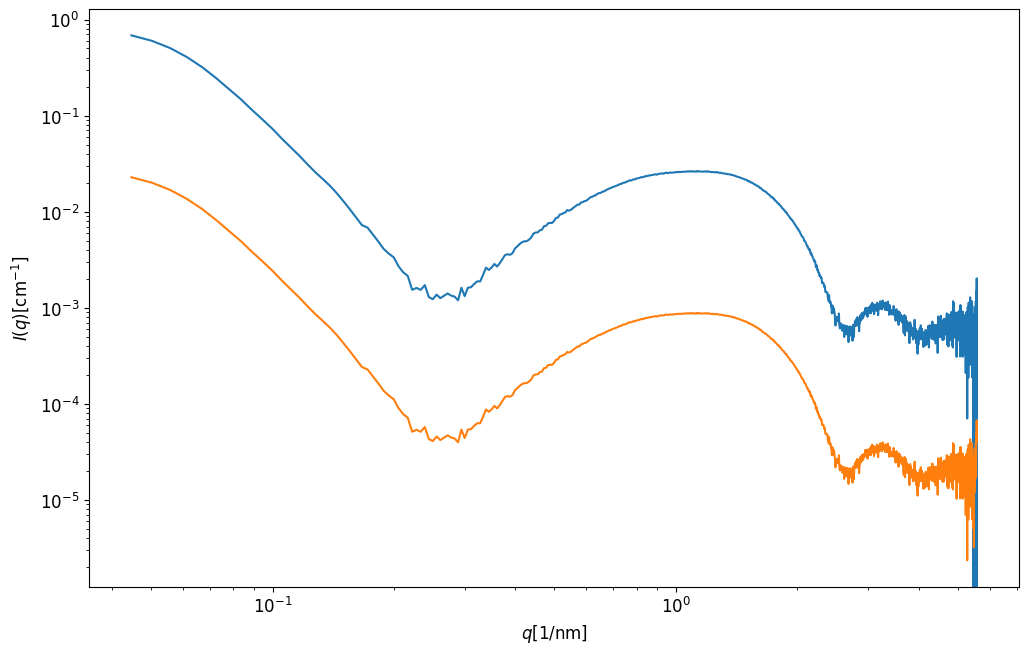

In [4]:
# EXPLORE ERROR MODELS #############
sample = "BIV_S1" # "BII_S9_15mM_LV4_PBS_FVII"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

Ierr_op1 = BM29.Poisson_error_lowq_highq(q, Ierr)
Ierr_op2 = BM29.op_error_classic(q, I)
Ierr_op3 = BM29.Poisson_error_focus_minimum_highq(q, Ierr)
Ierr_op4 = BM29.Poisson_error_focus_lowq_and_minimum(q, Ierr)

plt.figure(figsize=(12, 7.5))
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.loglog(q, I, label="SAXS data")
# plt.loglog(q, Ierr, label="Poisson_error")
# plt.loglog(q, Ierr_op1, label="improved_Poisson_error_low_high")
plt.loglog(q, Ierr_op2, label="op_error_classic")
# plt.loglog(q, Ierr_op3, label="op_error_focus_minimum_high")
# plt.loglog(q, Ierr_op4, label="op_error_focus_lowq_and_minimum")
# plt.axvline(x = 0.07, c="black", label="cutoff")
# plt.legend(loc="upper right")

In [5]:
# CALCULATE CHI2
sample = "BIV_S11" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        print(dir_name)
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

mask = (q >= 0.07) & (q <= 5.1)
q    = q[mask]
I    = I[mask]
Ierr = Ierr[mask]

Ierr_op = BM29.op_error_classic(q, I) #(q, I) #Ierr # BM29.improved_Poisson_error_low_high(q, Ierr)

p0_sph_asym    = BM29.best_fits[sample]["ULV_spheric_asym_C4"][1]
# p0_sph_asym = [15.19, 4.606, 0.988, 1.16, 0.5015, 0.4404, 0.8889, 1.786, 0.0001735, 0.0006513]
p0_ellips_asym =  BM29.best_fits[sample]["ULV_ellipsoid_asym_C4"][1]
# p0_ellips_asym =  [16.01, 3.748, 0.9081, 0.2396, 1.508, 1.018, 0.3356, 0.3169, 0.6991, 1.904, 3.16e-07, 0.0004296]


sample_BIV_S110000-subtract


In [6]:
# p0_ellips_asym = [9.9997, 5.9694, 1.1317, 0.10304, 1.8799, 1.0389, 0.30377, 0.44115, 0.89864, 1.7498, 5.487e-07, 0.0002264] (LV4 pure best fit BM26)

fit_function_name = "ULV_spheric_asym_C4"
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
I_sph_asym = fit_function(q, *p0_sph_asym)
residuals     = I - I_sph_asym
chi2_sph_asym = np.sum((residuals / Ierr_op)**2) / (len(I) - len(p0_sph_asym) - 1)

fit_function_name = "ULV_ellipsoid_asym_C4"
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale, c4: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale,   0, 0, c4)
I_ellips_asym = fit_function(q, *p0_ellips_asym)
residuals     = I - I_ellips_asym
chi2_ellips_asym = np.sum((residuals / Ierr_op)**2) / (len(I) - len(p0_ellips_asym) - 1)

print("For the sample ", BM29.sample_dict[sample])
print("chi2 of ULV_spheric_asym_C4: ", chi2_sph_asym)
print("chi2 of ellipsoid_asym_C4: ", chi2_ellips_asym)

plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, Ierr_op, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='SAXS data', zorder=1)
plt.loglog(q, I_sph_asym, label="sph asym")
plt.loglog(q, I_ellips_asym, label="ellips asym")
plt.legend()

TypeError: <lambda>() missing 12 required positional arguments: 'R', 'sigma_R', 'eps', 'sigma_eps', 'rho_h1', 'rho_h2', 'sigma_h1', 'sigma_h2', 'sigma_c', 'z_h', 'scale', and 'c4'

In [7]:
# write params into BM29.best_fits
# importlib.reload(BM29)
# save_best_fit(sample, "ULV_spheric_asym_C4", p0_sph_asym)
# save_best_fit(sample, "ULV_ellipsoid_asym_C4", p0_ellips_asym)



In [8]:
who = [
    "BII_S9",

    "BIV_S1",
    "BIV_S2",
    "BIV_S3",
    "BIV_S4",
    "BIV_S5",
    "BIV_S6",
    "BIV_S7",
    "BIV_S8",
    "BIV_S9",
    "BIV_S10",
]

for sample in who:
    R_spheric = BM29.best_fits[sample]["ULV_spheric_asym_C4"][1][0]
    R_ellips  = BM29.best_fits[sample]["ULV_ellipsoid_asym_C4"][1][0]
    Rmean = np.mean([R_spheric, R_ellips])
    Rstd = np.std([R_spheric, R_ellips])
    print(f"{sample} has R_mean = {Rmean:.4g} +- {Rstd:.4g} nm")

BII_S9 has R_mean = 15.99 +- 0.1 nm
BIV_S1 has R_mean = 16.36 +- 0.1 nm


KeyError: 1

In [9]:
who = [
    "BII_S9",

    "BIV_S21",
    "BIV_S22",
    "BIV_S23",
    "BIV_S24",
    "BIV_S25",
    "BIV_S26",
    "BIV_S27",
    "BIV_S28",
    "BIV_S29",
    "BIV_S30"
]

for sample in who:
    R_spheric = BM29.best_fits[sample]["ULV_spheric_asym_C4"][1][0]
    R_ellips  = BM29.best_fits[sample]["ULV_ellipsoid_asym_C4"][1][0]
    Rmean = np.mean([R_spheric, R_ellips])
    Rstd = np.std([R_spheric, R_ellips])
    print(f"{sample} has R_mean = {Rmean:.4g} +- {Rstd:.4g} nm")

BII_S9 has R_mean = 15.99 +- 0.1 nm


KeyError: 1

Computing I(q): 100%|████████████████████████| 908/908 [00:01<00:00, 834.13it/s]

For the sample  2 mM LVs
chi2 of ULV_spheric_asym_C4_lognormal:  10.314730936105192


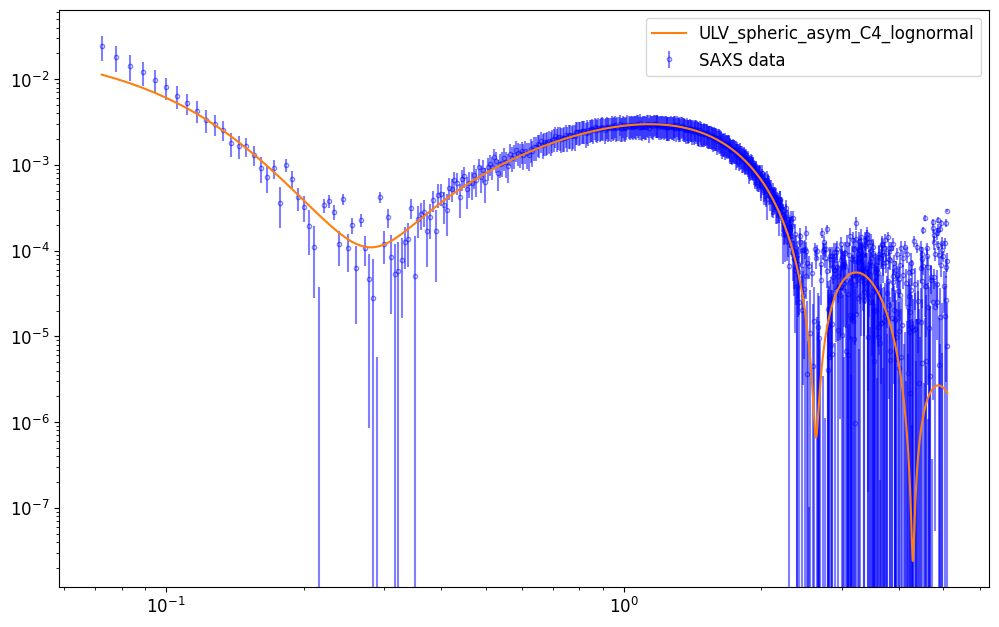

In [11]:
fit_function_name = "ULV_spheric_asym_C4_lognormal"
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)

p0_lognormal = [11.69, 0.3445, 1.467, 1.03, 0.4122, 0.3952, 0.8777, 1.833, 4.768e-08, 3.347e-39]

sample = "BII_S4"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, I_err_Poisson = np.loadtxt(sub_dat_path, unpack=True)

mask = (q >= 0.07) & (q <= 5.1)
q    = q[mask]
I    = I[mask]
I_err_Poisson = I_err_Poisson[mask]

Ierr = BM29.Poisson_error_focus_minimum_highq(q, I_err_Poisson)

thinning = 2
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = Ierr[::thinning]

# ========================== Setting Bounds ==============================
# p0         = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,   c4] #,      c2,      c3,      c4]
lower_bounds = [ 9.0,          0,      0.8,      0.8,        0.13,      0.13,      0.5,    1.5,      0,   0] #,       0,       0, -np.inf]
upper_bounds = [  25,          1,      3.0,      1.7,         0.6,       0.6,      1.2,      2,      1,   1] #,       4,     0.5, +np.inf]
#======================== Fit ===========================================

param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]
#=========================== Plot ===========================================
I_lognormal = fit_function(q, *p0_lognormal)
residuals     = I - I_lognormal
chi2_lognormal = np.sum((residuals / Ierr_op)**2) / (len(I) - len(p0_lognormal) - 1)

print("For the sample ", BM29.nice_sample_names[sample])
print("chi2 of ULV_spheric_asym_C4_lognormal: ", chi2_lognormal)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, Ierr_op, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='SAXS data', zorder=1)
plt.loglog(q, I_lognormal, label="ULV_spheric_asym_C4_lognormal")
plt.legend()